# 🌿 Plant Doctor
Upload a photo of a plant and get a structured health report, a care plan,
and illustrative recovery images, all powered by Google's Gemini API.

> ⚠️ Plant Doctor gives *possible* explanations from a single photo. It is not a definitive diagnosis.

## 1. Setup

In [1]:
%pip install -q google-genai pillow ipywidgets

Note: you may need to restart the kernel to use updated packages.


In [3]:
import json
import os
import time
from datetime import datetime
from getpass import getpass
from io import BytesIO

import ipywidgets as widgets
from google import genai
from google.genai import errors, types
from IPython.display import display
from PIL import Image

# --- Configuration -----------------------------------------------------------
TEXT_MODEL = "gemma-4-26b-a4b-it"
IMAGE_MODEL = "gemini-nano-banana-2.1"
REQUEST_TIMEOUT_MS = 300_000  # 5 minutes; also sent to the server as its deadline
MAX_IMAGE_SIDE = 1024         # downscale photos before upload for faster requests
MAX_RETRIES = 3               # retries on temporary server errors (5xx)

SEVERITY_LEVELS = ("Healthy", "Mild", "Moderate", "Severe", "Uncertain")
RECOVERY_STAGES = (
    "Possible appearance after 1 week of care",
    "Possible appearance after 2 weeks of care",
    "Possible appearance after 4 weeks of care",
)

# --- API client --------------------------------------------------------------
# Never paste your key into the notebook. It is read from the environment,
# or requested securely the first time.
if not os.environ.get("GEMINI_API_KEY"):
    os.environ["GEMINI_API_KEY"] = getpass("Enter your Google AI API key: ")

client = genai.Client(
    api_key=os.environ["GEMINI_API_KEY"],
    http_options=types.HttpOptions(timeout=REQUEST_TIMEOUT_MS),
)
print("Connected successfully! 🌿")

Connected successfully! 🌿


## 2. Upload a plant photo

In [4]:
upload = widgets.FileUpload(accept="image/*", multiple=False)
display(upload)

FileUpload(value=(), accept='image/*', description='Upload')

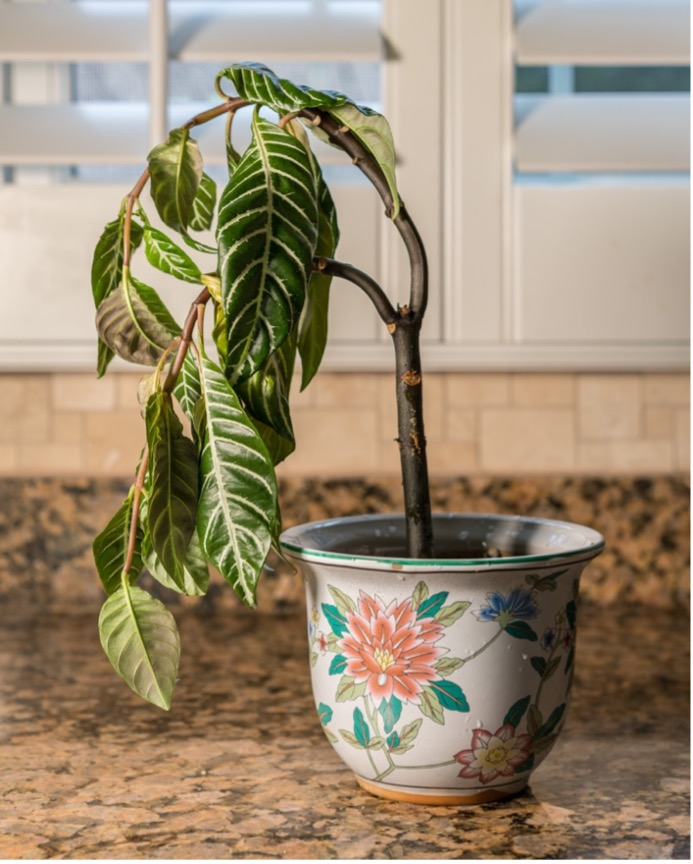

In [5]:
def load_uploaded_image(upload_widget):
    """Return the uploaded file as an RGB PIL image, or None if nothing was uploaded."""
    if not upload_widget.value:
        return None
    content = upload_widget.value[0]["content"]
    image = Image.open(BytesIO(content)).convert("RGB")
    image.thumbnail((MAX_IMAGE_SIDE, MAX_IMAGE_SIDE))  # keeps aspect ratio, never upscales
    return image


plant_image = load_uploaded_image(upload)

if plant_image is None:
    print("Please upload a plant image above, then re-run this cell.")
else:
    display(plant_image)

## 3. Helper functions

In [6]:
def parse_json_response(text):
    """Parse a JSON reply from the model, tolerating Markdown code fences."""
    cleaned = text.strip().removeprefix("```json").removeprefix("```").removesuffix("```").strip()
    try:
        return json.loads(cleaned)
    except json.JSONDecodeError:
        print("The AI did not return valid JSON. Raw response:")
        print(cleaned)
        return None


def generate_with_retry(**kwargs):
    """Call generate_content, retrying temporary server errors (e.g. 503/504) with a short backoff."""
    for attempt in range(1, MAX_RETRIES + 1):
        try:
            return client.models.generate_content(**kwargs)
        except errors.ServerError as error:
            if attempt == MAX_RETRIES:
                raise
            wait = 5 * attempt
            print(f"⚠️ Server error ({error.code}); retrying in {wait}s (attempt {attempt}/{MAX_RETRIES})...")
            time.sleep(wait)


def ask_model(prompt, image=None):
    """Send a prompt (and optional image) to the text model and return its reply."""
    contents = [prompt, image] if image is not None else prompt
    response = generate_with_retry(model=TEXT_MODEL, contents=contents)
    return response.text.strip()


def print_section(title, items):
    """Print a titled list. Items may be strings or dicts."""
    print(f"\n{title}")
    print("-" * 35)

    if not items:
        print("No information available.")
        return

    if not isinstance(items, list):
        print(items)
        return

    for item in items:
        if isinstance(item, dict):
            for key, value in item.items():
                print(f"{key.replace('_', ' ').title()}: {value}")
            print()
        else:
            print("•", item)

## 4. Analyze the plant

In [7]:
ANALYSIS_PROMPT = """
You are Plant Doctor, an AI-powered plant health assistant.

Examine the uploaded plant image and return your analysis
using the following JSON structure:

{
    "plant_identification": {
        "common_name": "",
        "scientific_name": "",
        "identification_confidence": ""
    },
    "visible_symptoms": [],
    "possible_health_problems": [
        {"problem": "", "reason": "", "likelihood": ""}
    ],
    "environmental_factors": [],
    "recommended_actions": [],
    "monitoring_advice": [],
    "overall_assessment": ""
}

Rules:
- Identify the plant only if the image provides enough evidence.
- Describe only symptoms visible in the photograph.
- Distinguish observations from possible explanations.
- Never claim a definitive disease diagnosis.
- Do not invent symptoms.
- Explain uncertainty.
- Give practical and safe plant-care recommendations.
- Return valid JSON only, without Markdown code fences.
"""


def analyze_plant(image):
    return parse_json_response(ask_model(ANALYSIS_PROMPT, image))


plant_data = analyze_plant(plant_image)

if plant_data:
    print("✅ Plant report created!")

✅ Plant report created!


In [8]:
def assess_severity(plant_data):
    """Classify overall plant condition as one of SEVERITY_LEVELS."""
    prompt = f"""
Based on this plant health report, classify its visible condition.

Report:
{json.dumps(plant_data)}

Choose exactly one: {", ".join(SEVERITY_LEVELS)}.
Consider only the evidence in the report.
Return only the classification word.
"""
    answer = ask_model(prompt).strip(" .*\n").capitalize()
    return answer if answer in SEVERITY_LEVELS else "Uncertain"


severity = assess_severity(plant_data)
print("Plant condition:", severity)

Plant condition: Severe


In [9]:
def display_plant_report(data, severity):
    identity = data.get("plant_identification", {})

    print("🌿 PLANT DOCTOR – HEALTH REPORT")
    print("=" * 45)
    print("\n🌱 PLANT IDENTIFICATION")
    print("Common name:", identity.get("common_name", "Unknown"))
    print("Scientific name:", identity.get("scientific_name", "Unknown"))
    print("Confidence:", identity.get("identification_confidence", "Unknown"))
    print("\n🩺 OVERALL CONDITION")
    print(severity)

    sections = [
        ("🔍 Visible Symptoms", "visible_symptoms"),
        ("⚠️ Possible Health Problems", "possible_health_problems"),
        ("🌤️ Environmental Factors", "environmental_factors"),
        ("💧 Recommended Actions", "recommended_actions"),
        ("📅 Monitoring Advice", "monitoring_advice"),
    ]
    for title, key in sections:
        print_section(title, data.get(key))

    print_section("📝 OVERALL ASSESSMENT", data.get("overall_assessment"))


display_plant_report(plant_data, severity)

🌿 PLANT DOCTOR – HEALTH REPORT

🌱 PLANT IDENTIFICATION
Common name: Chinese Evergreen
Scientific name: Aglaonema spp.
Confidence: High

🩺 OVERALL CONDITION
Severe

🔍 Visible Symptoms
-----------------------------------
• Severe wilting and drooping of leaves
• Loss of turgidity in the foliage
• Bending of the main stem under the weight of the limp leaves

⚠️ Possible Health Problems
-----------------------------------
Problem: Underwatering
Reason: The dramatic loss of leaf firmness is a classic sign that the plant's cells lack water pressure.
Likelihood: High

Problem: Overwatering or Root Rot
Reason: If the soil is constantly saturated, roots may decay, losing their ability to transport water to the leaves, which paradoxically causes wilting.
Likelihood: Medium


🌤️ Environmental Factors
-----------------------------------
• Indoor environment
• Proximity to a window (potential exposure to temperature fluctuations or direct sunlight)

💧 Recommended Actions
---------------------------

In [10]:
# Keep a timestamped record so future check-ups can be compared against it
health_record = {
    "date": datetime.now().isoformat(),
    "severity": severity,
    "plant_data": plant_data,
}

with open("plant_health_record.json", "w", encoding="utf-8") as f:
    json.dump(health_record, f, indent=2)

print("✅ Health record saved to plant_health_record.json")

✅ Health record saved to plant_health_record.json


## 5. Personalized care plan

In [11]:
CARE_PLAN_PROMPT = """
You are an experienced plant-care assistant.

Create a practical care plan based on this plant health report:

{report}

Return valid JSON with this structure:

{{
    "watering": {{"recommendation": "", "frequency": "", "warning": ""}},
    "sunlight": {{"recommendation": "", "ideal_conditions": ""}},
    "soil_and_drainage": "",
    "pest_management": "",
    "additional_care": [],
    "weekly_checklist": [],
    "important_warnings": []
}}

Rules:
- Consider the identified plant's actual needs.
- Do not recommend watering on a fixed schedule without considering soil moisture.
- Do not recommend fertilizer unless appropriate.
- Avoid unnecessary chemicals.
- Never invent environmental conditions.
- If information is missing, say what the owner should check.
- Make recommendations simple and practical.
- Return valid JSON only.
"""


def generate_care_plan(plant_data):
    prompt = CARE_PLAN_PROMPT.format(report=json.dumps(plant_data, indent=2))
    return parse_json_response(ask_model(prompt))


care_plan = generate_care_plan(plant_data)

if care_plan:
    print("🌿 Your personalized care plan is ready!")

🌿 Your personalized care plan is ready!


In [12]:
def display_care_plan(plan):
    print("🌱 PLANT DOCTOR – PERSONALIZED CARE PLAN")
    print("=" * 50)

    for section in ("watering", "sunlight"):
        print_section(section.title(), [
            {key: value} for key, value in plan.get(section, {}).items()
        ])

    for title, key in [
        ("Soil and Drainage", "soil_and_drainage"),
        ("Pest Management", "pest_management"),
        ("Additional Care", "additional_care"),
        ("Weekly Checklist", "weekly_checklist"),
        ("Important Warnings", "important_warnings"),
    ]:
        print_section(f"🌿 {title}", plan.get(key))


if care_plan:
    display_care_plan(care_plan)

🌱 PLANT DOCTOR – PERSONALIZED CARE PLAN

Watering
-----------------------------------
Recommendation: Check soil moisture by inserting a finger 1-2 inches deep. If dry, water thoroughly until water drains out of the bottom. If the soil feels wet or muddy, withhold water immediately.

Frequency: Only when the top 1-2 inches of soil are dry; do not use a fixed calendar schedule.



Sunlight
-----------------------------------
Recommendation: Provide bright, indirect light.

Ideal Conditions: Avoid exposure to harsh, direct midday sun, especially if near a window.


🌿 Soil and Drainage
-----------------------------------
Use well-draining potting soil. Ensure the container has functional drainage holes. If roots appear mushy upon inspection, repot the plant in fresh, well-draining soil.

🌿 Pest Management
-----------------------------------
Regularly inspect the undersides of leaves and stems for any signs of pests.

🌿 Additional Care
-----------------------------------
• Monitor the plan

In [13]:
def build_checklist(plan):
    items = plan.get("weekly_checklist", []) if plan else []
    boxes = [widgets.Checkbox(value=False, description=str(item), indent=False) for item in items]
    return widgets.VBox([widgets.HTML("<h3>🌱 This Week's Plant Care Tasks</h3>"), *boxes])


display(build_checklist(care_plan))

## 6. Illustrative recovery images
These are AI-generated *possible* outcomes, not predictions.

In [ ]:
!pip install -q diffusers transformers accelerate torch

Using device: mps


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion_img2img.StableDiffusionImg2ImgPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


Model loaded, generating...


  0%|          | 0/12 [00:00<?, ?it/s]

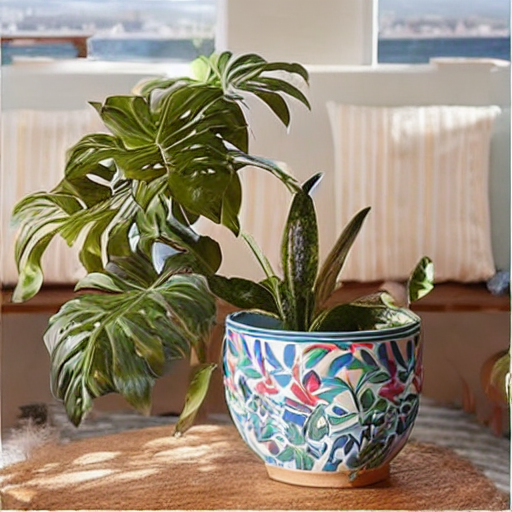

In [15]:
import torch
from diffusers import StableDiffusionImg2ImgPipeline

device = "mps" if torch.backends.mps.is_available() else ("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

pipe = StableDiffusionImg2ImgPipeline.from_pretrained(
    "stable-diffusion-v1-5/stable-diffusion-v1-5",
    torch_dtype=torch.float16 if device == "cuda" else torch.float32,
    safety_checker=None,
).to(device)
print("Model loaded, generating...")

result = pipe(
    prompt="the same houseplant in the same pot, healthy upright firm green leaves, photorealistic",
    negative_prompt="wilted, drooping, dead leaves, text, watermark, cartoon",
    image=plant_image.resize((512, 512)),
    strength=0.6,
    guidance_scale=8,
    num_inference_steps=20,
).images[0]

display(result)

In [16]:
stages = [
    # (label, prompt, strength)
    ("Day 1 (today)", None, None),  # your original photo, unchanged
    ("Week 1",
     "the same houseplant in the same pot, leaves slightly firmer and less droopy, early signs of recovery, photorealistic",
     0.35),
    ("Week 2",
     "the same houseplant in the same pot, mostly upright with firm green leaves, clearly recovering, photorealistic",
     0.50),
    ("Final (4 weeks)",
     "the same houseplant in the same pot, healthy upright firm green leaves, fully recovered, photorealistic",
     0.65),
]

negative_prompt = "wilted, drooping, dead leaves, text, watermark, cartoon"
base_image = plant_image.resize((512, 512))

timeline_images = {}

for label, prompt, strength in stages:
    if prompt is None:
        timeline_images[label] = base_image
        continue

    print(f"Generating: {label} ...")
    timeline_images[label] = pipe(
        prompt=prompt,
        negative_prompt=negative_prompt,
        image=base_image,
        strength=strength,
        guidance_scale=8,
        num_inference_steps=20,
        generator=torch.Generator("cpu").manual_seed(42),  # same seed keeps the plant consistent
    ).images[0]

print("✅ Done!")

Generating: Week 1 ...


  0%|          | 0/7 [00:00<?, ?it/s]

Generating: Week 2 ...


  0%|          | 0/10 [00:00<?, ?it/s]

Generating: Final (4 weeks) ...


  0%|          | 0/13 [00:00<?, ?it/s]

✅ Done!


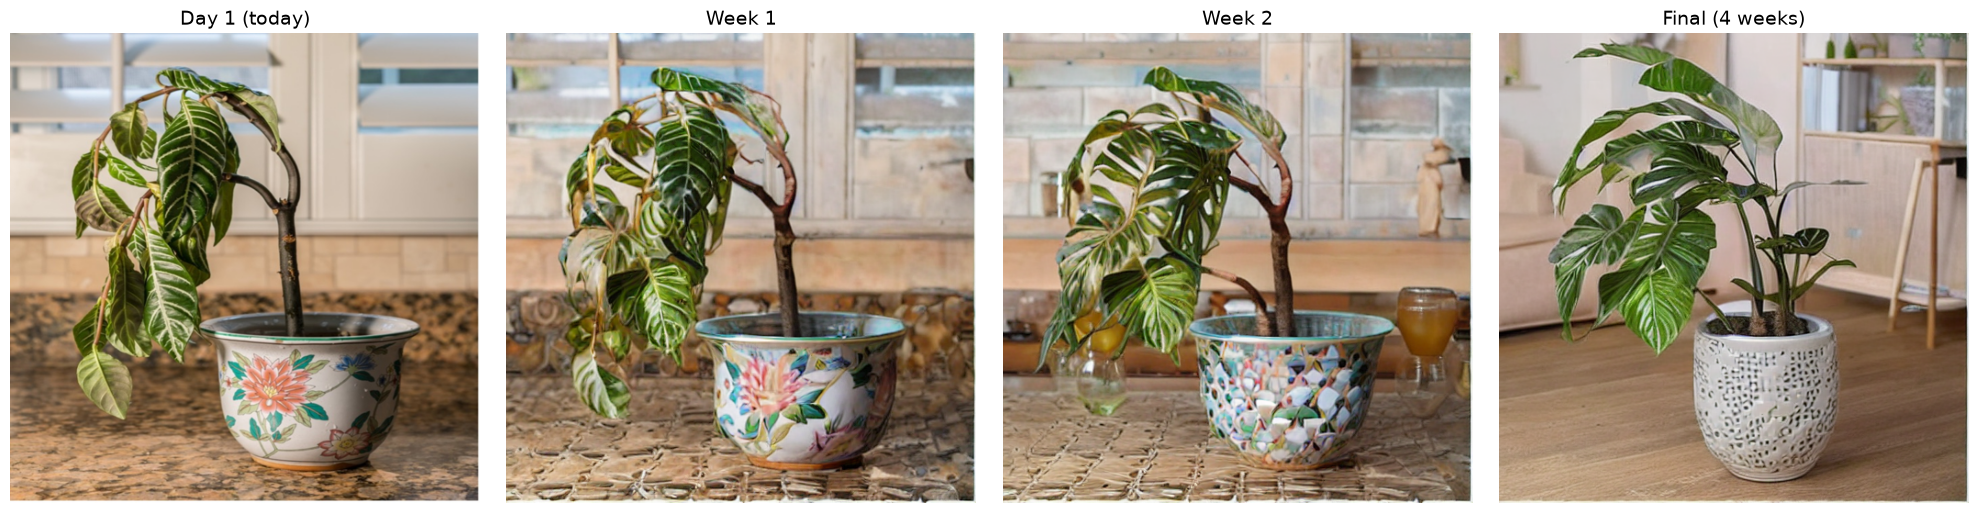

In [17]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, len(timeline_images), figsize=(5 * len(timeline_images), 5))

for ax, (label, img) in zip(axes, timeline_images.items()):
    ax.imshow(img)
    ax.set_title(label, fontsize=14)
    ax.axis("off")

plt.tight_layout()
plt.show()